# JavaScript: Looping and Branching

A comprehensive guide to iteration and branching in JavaScript (ECMAScript 2022), covering the full range of loop constructs, advanced iteration concepts, and conditional branching patterns including the nullish coalescing operator.

## Table of Contents

1. [Module 01: Understanding Iteration Thoroughly](#module-01-understanding-iteration-thoroughly)
   - JavaScript engines, prerequisites, setup
   - The `for` loop
   - Iterables and `for-of`
   - `forEach()`, `while`, `do-while`
   - Sparse arrays, `continue` and `break`
   - Array search methods
2. [Module 02: Grasping Advanced Iteration Concepts](#module-02-grasping-advanced-iteration-concepts)
   - `for-in` loop
   - `for-await-of` loop
   - Performance considerations
3. [Module 03: Branching and Its Pitfalls](#module-03-branching-and-its-pitfalls)
   - `if/else if/else`
   - `switch` and fall-through
   - Ternary operator
   - Nullish coalescing operator (`??`)

**Demos:** [`01-looping-branching-demos/`](01-looping-branching-demos/)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Understanding Iteration Thoroughly

_Covers the JavaScript engine context, all common loop constructs, iterables, sparse arrays, and array search methods._

### JavaScript Engines

JavaScript code is executed by a JavaScript engine. The two dominant engines are V8 (used in Chrome and Node.js) and SpiderMonkey (used in Firefox). Both implement the ECMAScript standard.


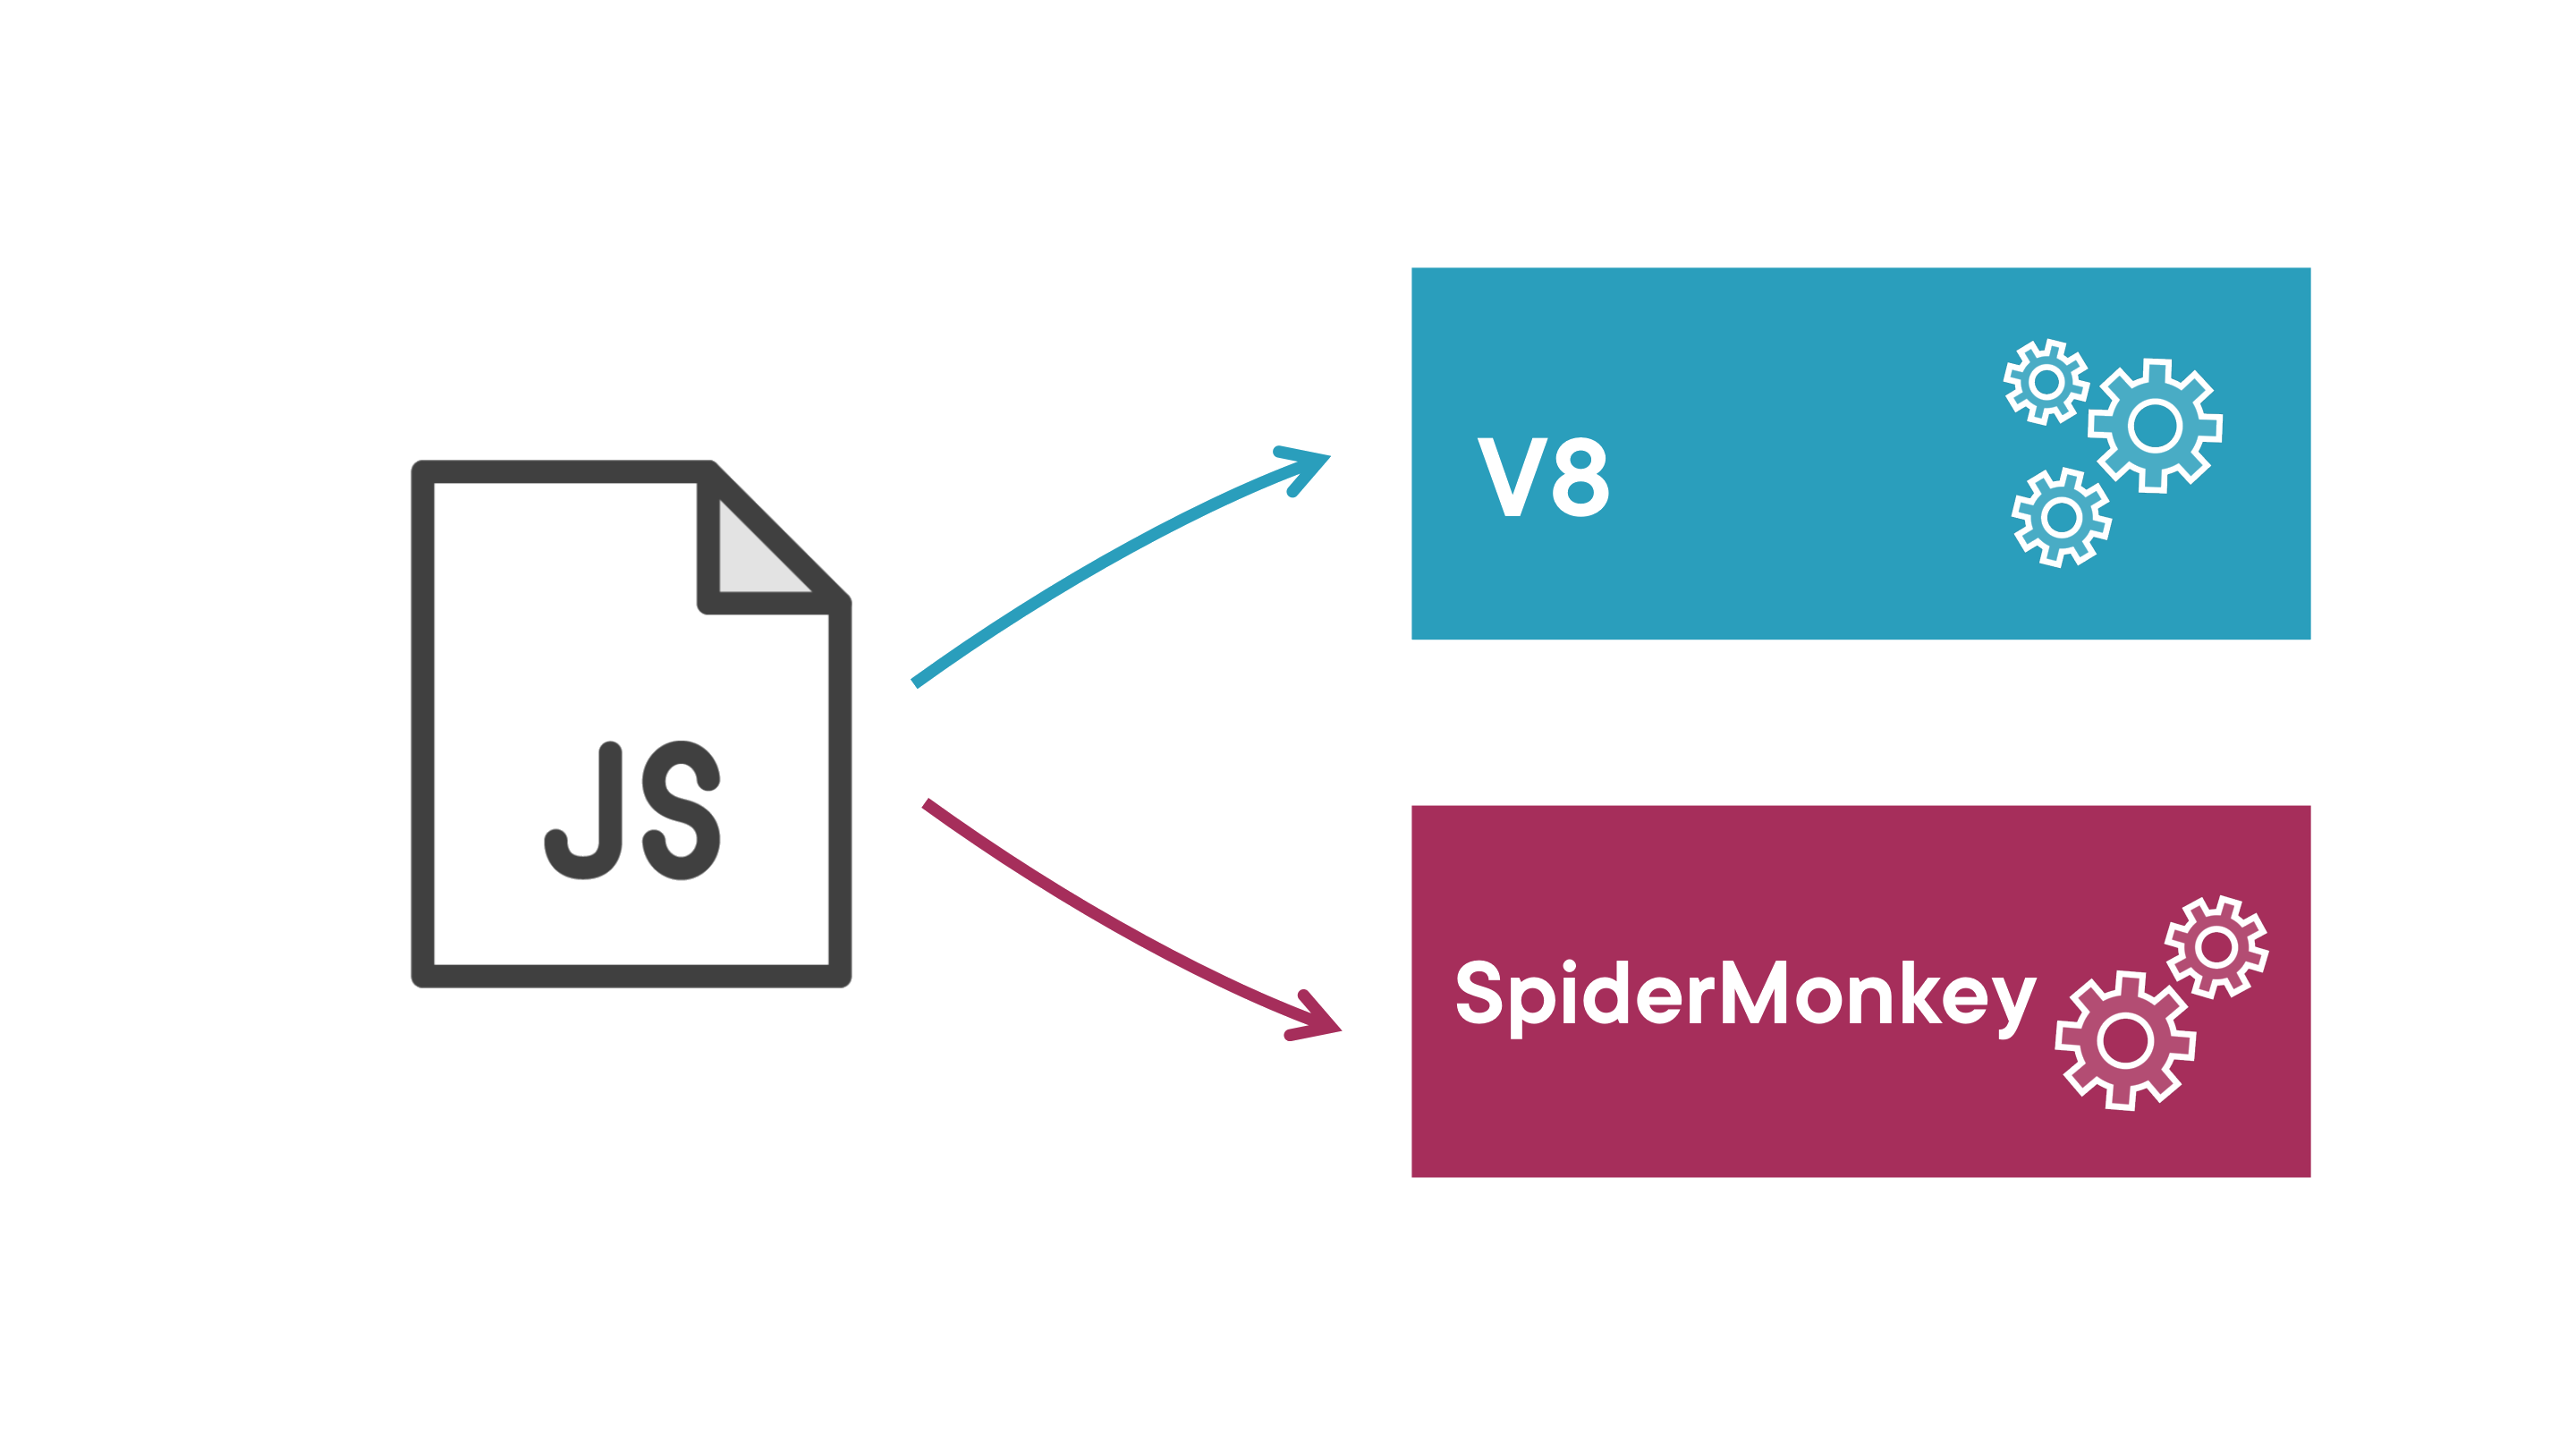

In [2]:
render_diagram(Path("assets/01-js-engines.png"))

### Prerequisites and Setup

**Prerequisites:**
- General programming concepts — data types, functions/methods
- HTML basics
- A code editor

**Setup used in this course:**
- OS: Windows
- IDE: VS Code
- Node.js

### Version

This course targets **ECMAScript 2022** and is 100% applicable to that version.

### The `for` Loop

The classic `for` loop has three parts: initialiser, condition, and post-iteration expression.

```
for («init»; «condition»; «post_iter») {
  «statements»
}
```

**Common off-by-one pitfall** — using `<=` instead of `<` when iterating over an array by index reads past the last element, producing `undefined`:

```js
let strings = ["a", "b", "c"];

// Bug: <= strings.length goes one index too far
for (let i = 0; i <= strings.length; i++) {
  console.log("Element num " + strings[i]); // prints "undefined" on last iteration
}

// Correct: < strings.length
for (let i = 0; i < strings.length; i++) {
  console.log("Element: " + strings[i]);
}
```

### Iterables

An **iterable** is any object that implements the iteration protocol. Common iterables in JavaScript:

| Iterable | Notes |
|---|---|
| `Array` | Most common; supports `entries()` for index+value pairs |
| `HTMLCollection` | Returned by `getElementsByTagName()`; not an Array |
| `String` | Iterates over Unicode characters |
| `Set` | Unique values only |
| `Map` | Key-value pairs |

`HTMLCollection` implements `Iterable` (so `for-of` works) but is not an `Array`. Use `Array.from()` to convert it to an Array when you need Array methods.


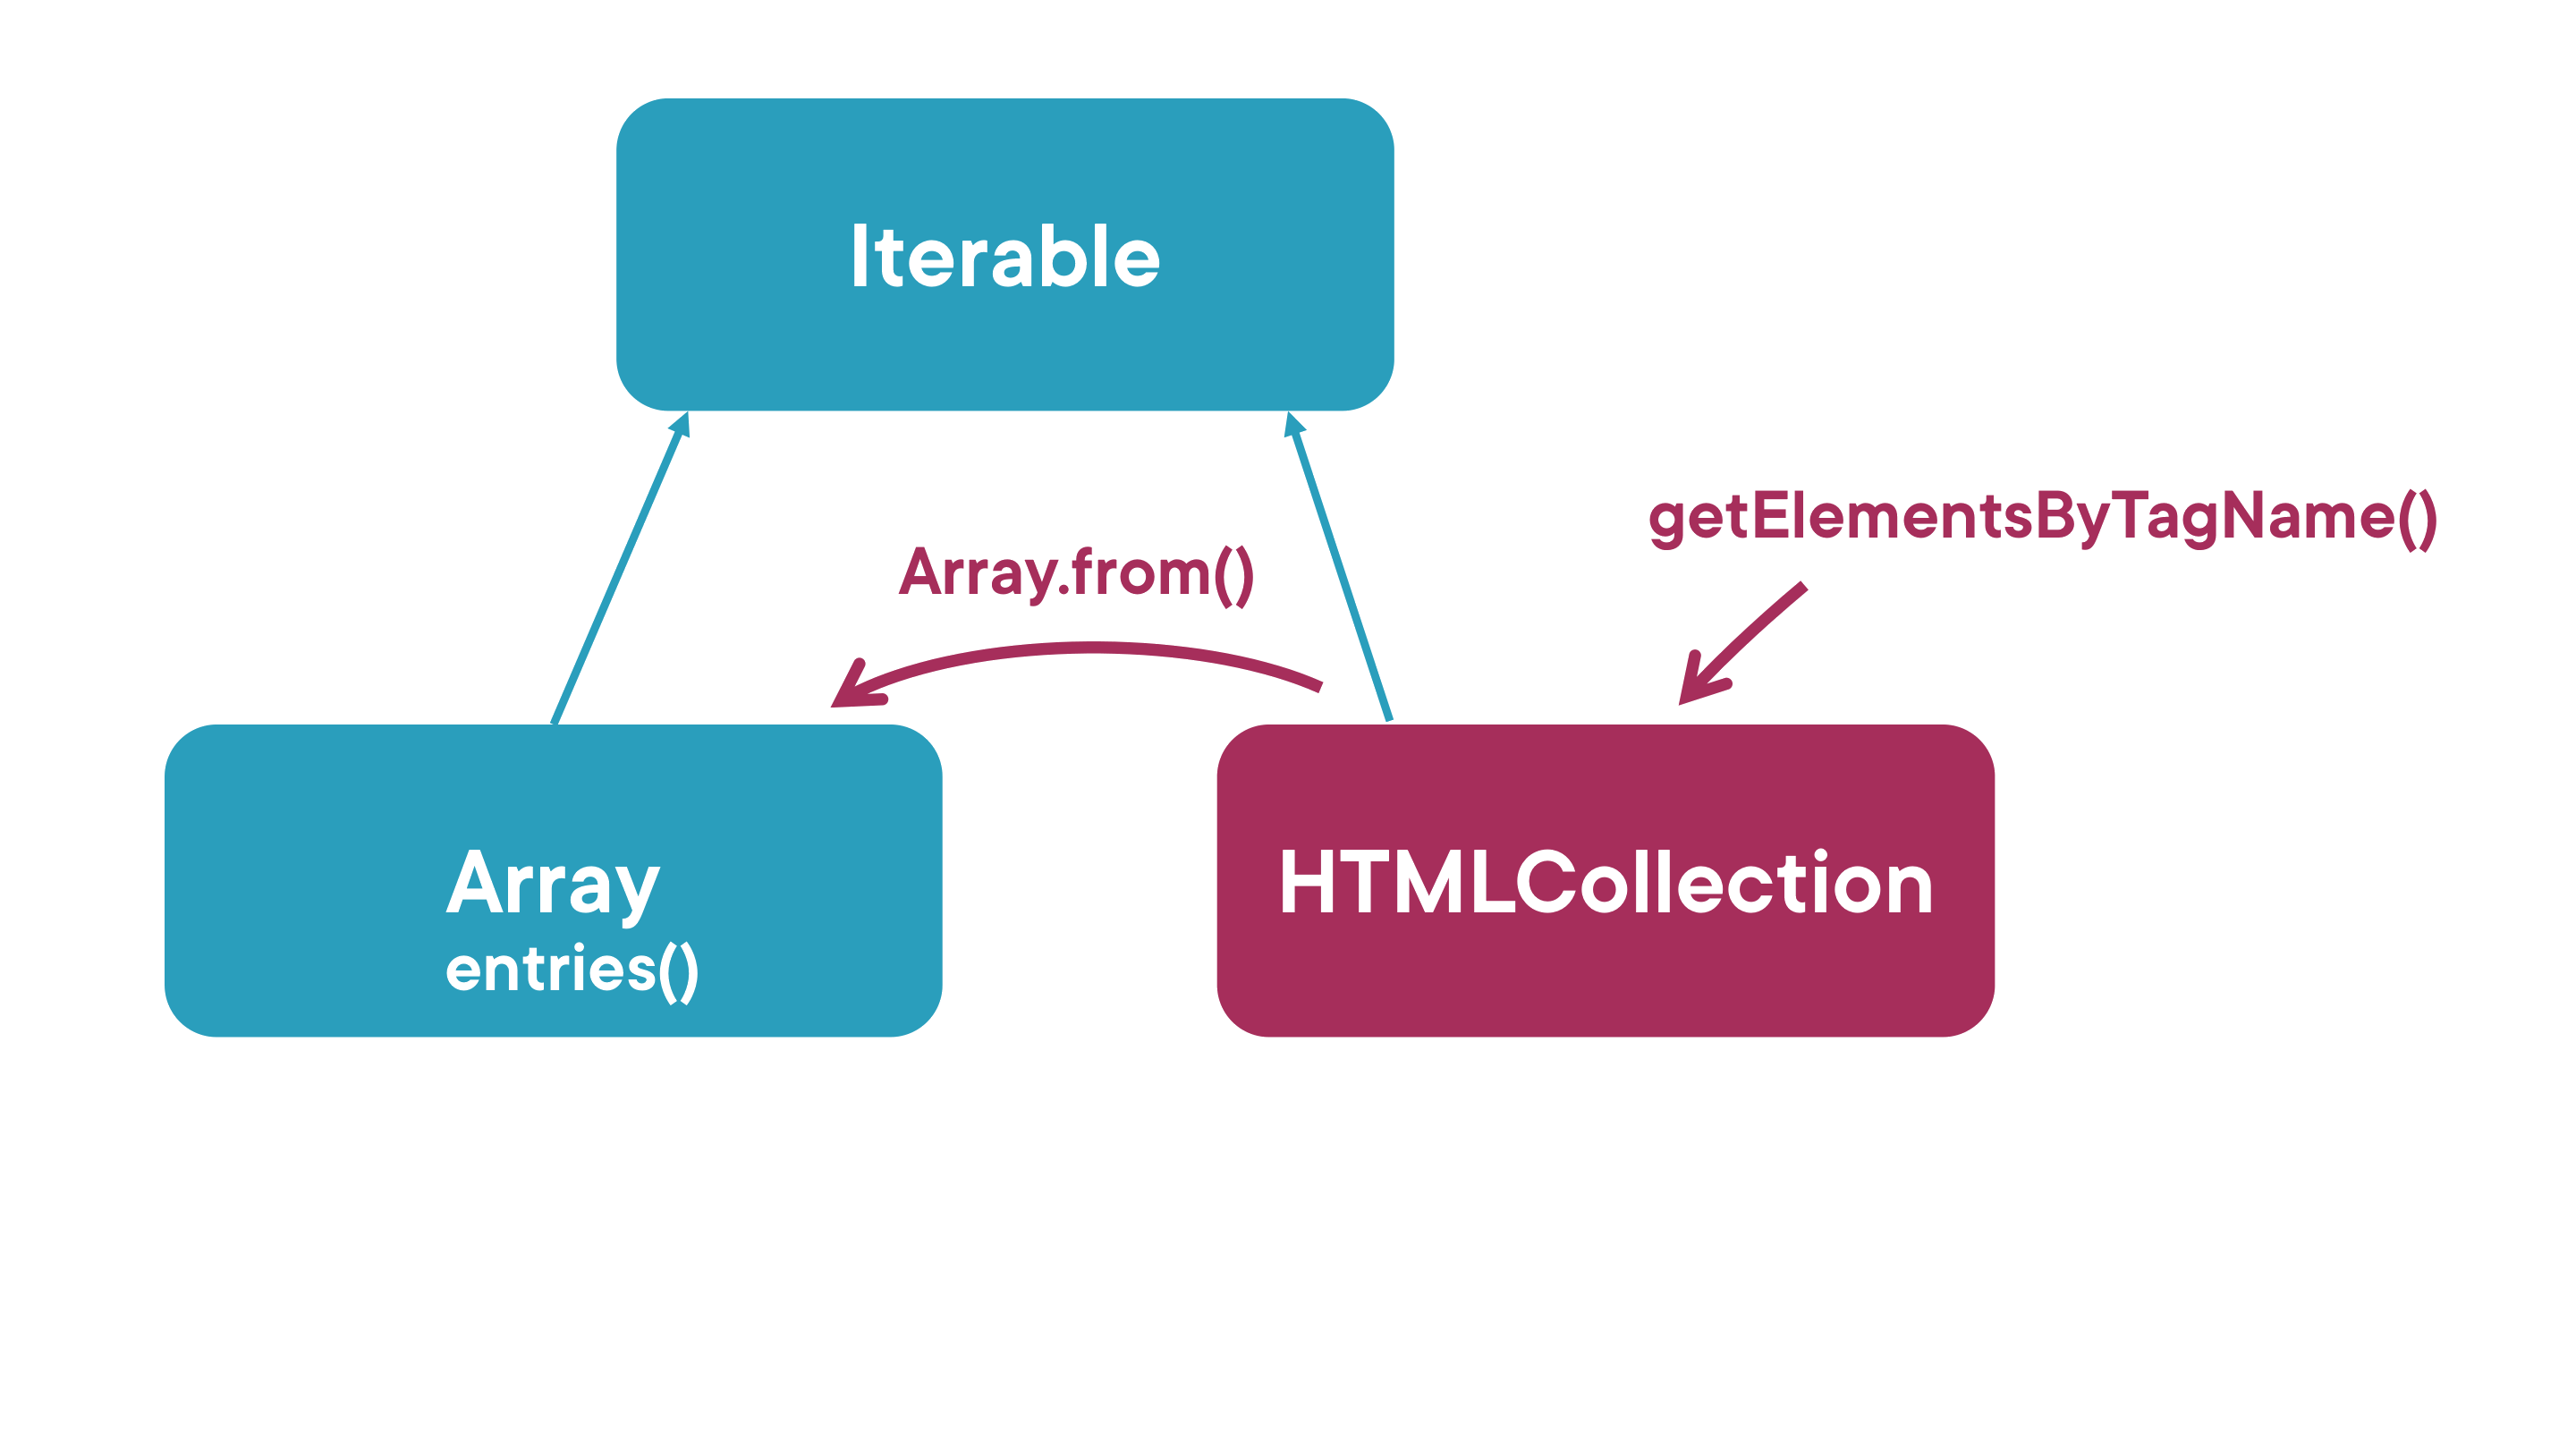

In [3]:
render_diagram(Path("assets/02-iterable-htmlcollection-relationship.png"))

### `for-of` and `forEach()`

`for-of` iterates over any iterable. `forEach()` is an Array method that takes a callback.

```js
// for-of: works on any iterable
for (let value of array) {
  // ...
}

// forEach: Array method, callback receives element (and optionally index, array)
array.forEach(e => console.log(e));
```

Both are more readable than a classic index-based `for` loop when you don't need the index.

### `while` and `do-while`

```js
// while: checks condition before each iteration
while (condition) {
  // executes zero or more times
}

// do-while: checks condition after each iteration
do {
  // executes at least once
} while (condition);
```

### `continue` and `break`

Inside any loop body, `continue` jumps to the next iteration and `break` exits the loop entirely.

```js
for (let i = 0; i < 10; i++) {
  if (i === 3) continue; // skip 3
  if (i === 7) break;    // stop at 7
  console.log(i);
}
```

### Sparse Arrays

JavaScript arrays can contain holes — `null`, `undefined`, or completely empty slots. This affects how different loop constructs behave.

```js
// arrays may have null, undefined, or empty slots
let array = [,,,,];      // 4 empty slots
array.length = 20;       // extend length without filling
array[30] = 100;         // index beyond length; creates more empty slots
delete array[5];         // creates an empty slot at index 5
```

- `for` loop iterates by index — will encounter `undefined` for empty slots.
- `for-of` also yields `undefined` for empty slots.
- `forEach()` **skips** empty slots entirely.
- `for-in` only visits defined properties.

### Array Search Methods

These Array methods let you search without writing an explicit loop:

| Method | Returns | Description |
|---|---|---|
| `find(predicate)` | First matching element or `undefined` | Stops at first match |
| `every(predicate)` | `boolean` | `true` if all elements satisfy the predicate |
| `some(predicate)` | `boolean` | `true` if at least one element satisfies the predicate |

```js
const prices = [10, 25, 5, 42, 3];

prices.find(p => p > 20);    // 25
prices.every(p => p > 0);    // true
prices.some(p => p > 40);    // true
```

### Module 01 Summary

| Loop | Use case |
|---|---|
| `for` | Index-based iteration, known count |
| `for-of` | Any iterable, value-only access |
| `forEach()` | Arrays only, callback-style, skips sparse slots |
| `while` | Condition-based, unknown count |
| `do-while` | Must execute at least once |

### Demo: Iteration Basics

Starter files covering the classic `for` loop, HTML stock list with `for-of`, and `for-in` on arrays and objects.

See [`01-looping-branching-demos/01-iteration-basics/`](01-looping-branching-demos/01-iteration-basics/) for the full demo.

```js
// 01-iteration-basics/_1for.js
console.log("Classic loop");
for (let step = 0; step <= 4; step++) {
    console.log('Walking east one step: ' + step);
}
```

---

## Module 02: Grasping Advanced Iteration Concepts

_Covers `for-in`, `for-await-of`, and practical advice on loop performance._

### `for-in` vs `for-of`

These two constructs look similar but serve entirely different purposes:

| | `for-of` | `for-in` |
|---|---|---|
| Introduced | ES6 | ES1 |
| Iterates over | **Values** of an iterable | **Property names** of an object |
| Use with arrays | Yes | **No** — order not guaranteed |
| Use with objects | No (objects are not iterable) | Yes |

```js
// for-of: iterates values — correct for iterables
for (let e of arr) { ... }

// for-in: iterates property names — correct for plain objects
for (let prop in obj) { ... }
```

**`for-in` on an object — order not guaranteed:**

```js
let someObj = {
  prop_1: "string",
  prop_2: false
};

for (let key in someObj) {
  console.log(key); // "prop_1", "prop_2" — but order is engine-dependent
}
```

### Choosing the Right Pattern for Objects

When iterating an object, pick the variant that gives you what you need:

```js
// Yes — recommended patterns for objects:
for (let e of iterable) {}                          // iterable values
for (let prop of Object.keys(obj)) { }              // own enumerable property names, ordered
for (let [key, value] of Object.entries(obj)) { }  // own key-value pairs, ordered
for (let prop in obj) { }                           // all enumerable props incl. inherited

// No — avoid:
for (let prop in array) { }  // wrong: iterates indices as strings + inherited props
```

`Object.keys()` and `Object.entries()` both return results in insertion order (for string keys) — making them preferable to `for-in` when order matters.

### `for-await-of` — Async Iteration

`for-await-of` is used to consume an **async iterable** — an object that yields Promises one at a time. It requires an `async` function context.

**Prerequisites:** Promises and async functions.

```js
for await (let e of asyncIterable) {
  // current iteration waits for the previous to complete
}
```

**Three patterns for async looping:**

```js
// Pattern 1: await a resolved batch (Promise.all) then loop synchronously
for (let p of await Promise.all(promises)) { }

// Pattern 2: regular for-of with await inside (independent iterations)
for (let e of items) {
  const res = await somethingAsync(e);
}

// Pattern 3: for-await-of on an async iterable (sequential, each depends on previous)
for await (let e of asyncIterable) {
  // use e
}
```

**Real-world example — paginated GitHub API (`02-advanced-iteration/_2for_await_of.js`):**

```js
import fetch from 'node-fetch';

(async () => {
  let count = 0;
  for await (const repo of fetchRepos('javascript')) {
    console.log(count + 1, repo.full_name);
    if (++count == 50) break;
  }
})();

async function* fetchRepos(query) {
  let url = `https://api.github.com/search/repositories?q=${query}`;
  while (url) {
    const response = await fetch(url, { headers: {'User-Agent': 'Custom Script'} });
    const body = await response.json();
    let nextPage = response.headers.get('Link').match(/<(.*?)>; rel="next"/);
    url = nextPage?.[1];
    for (let repo of body.items) {
      yield repo;
    }
  }
}
```

See [`01-looping-branching-demos/02-advanced-iteration/`](01-looping-branching-demos/02-advanced-iteration/) for the full demo.

### Performance Considerations

If you want to make a loop faster, two strategies have genuine impact:

1. **Optimize work done per iteration** — reduce work inside the loop body (fewer DOM accesses, fewer allocations, simpler computations)
2. **Reduce the number of iterations** — exit early with `break` or `find()` when you don't need all results

> **Book reference:** *High Performance JavaScript* (2010) is a classic, but its micro-optimization advice (e.g. caching `array.length`) is largely obsolete. As of 2022 there is no convincing evidence that such micro-optimisations make any significant difference on modern engines.

**Practical rule:** Write clear, readable loop code first. Only optimize after profiling shows a real bottleneck. Premature optimization wastes development time and can obscure intent.

### Module 02 Summary

- Use `for-in` for **plain object properties** only; never on arrays
- Prefer `Object.keys()` / `Object.entries()` over `for-in` when order matters
- Use `for-await-of` for **async iterables** where iterations depend on each other
- Optimise loops by reducing work per iteration and exiting early; don't micro-optimise blindly

---

## Module 03: Branching and Its Pitfalls

_Covers `if/else if/else`, `switch` with fall-through, the ternary operator, and the nullish coalescing operator (`??`)._

### `if / else if / else` vs `switch`

When you have many branches on the same value, `switch` is more readable than a long `if/else if` chain:

```js
// if/else if chain — verbose for many cases
if (val === 'a') { ... }
else if (val === 'b') { ... }
else if (val === 'c') { ... }

// switch — cleaner for multiple cases on one value
switch (val) {
  case 'a':
    // ...
    break;
  case 'b':
    // ...
    break;
  case 'c':
    // ...
    break;
}
```

### `switch` Fall-Through

Without a `break`, execution **falls through** to the next case. This is usually a bug, but can be used deliberately to share a handler across multiple cases:

```js
// Bug: each case falls through to the next
switch (month) {
  case 'Jan':
    return 'Winter'; // this also runs for Feb!
  case 'Feb':
    return 'Winter';
}

// Intentional fall-through: share the same return across cases
switch (month) {
  case 'Jan':
  case 'Feb':
    return 'Winter'; // both Jan and Feb reach this return
}
```

The intentional pattern (stacking cases without code between them) is idiomatic JavaScript for grouping equivalent cases.

### Ternary Operator

The ternary operator is a compact inline conditional: `condition ? valueIfTrue : valueIfFalse`.

```js
let result = someExpression ? a : b;
```

A common use-case is providing a fallback when a value might be `null` or `undefined`:

```js
// Verbose: explicit null/undefined check
let value = (a !== undefined && a !== null) ? a : backup;
```

This pattern is so common that ES2020 introduced a dedicated operator for it.

### Nullish Coalescing Operator (`??`)

The `??` operator returns the right-hand side operand when the left-hand side is **`null` or `undefined`** (nullish), and returns the left-hand side otherwise.

```js
// Old: verbose explicit check
a !== undefined && a !== null ? a : b;

// New (ES2020): exactly equivalent, much cleaner
a ?? b;
```

**Key distinction vs. `||`:**

```js
// || returns right-hand side for ANY falsy value (0, "", false, null, undefined)
0 || "default"     // "default"  — probably wrong if 0 is a valid value
"" || "default"    // "default"  — probably wrong if empty string is valid

// ?? only triggers for null/undefined
0 ?? "default"     // 0          — correct: 0 is a valid value
"" ?? "default"    // ""         — correct: empty string is a valid value
null ?? "default"  // "default"  — correct: null means missing
```

Use `??` instead of `||` whenever `0`, `false`, or `""` are valid values that should be preserved.

### Demo: Branching Patterns

See [`01-looping-branching-demos/03-branching/`](01-looping-branching-demos/03-branching/) for the starter file with a stock object for `if/else` and `switch` exercises.

```js
// 03-branching/_1if_else.js
let stock = {
    "name": "Google",
    "price": 100,
};

// Example: branch on stock price
if (stock.price > 200) {
    console.log("Expensive");
} else if (stock.price > 50) {
    console.log("Mid-range");
} else {
    console.log("Affordable");
}
```

### Module 03 Summary

- Use `switch` over long `if/else if` chains when comparing one value to many discrete options
- Intentional fall-through (stacking cases) is idiomatic; accidental fall-through is a common bug — always add `break`
- The ternary operator `? :` is a compact inline conditional
- Prefer `??` over `||` for null/undefined fallbacks when `0`, `false`, or `""` are valid values

### Further Reading

- [javascript.info](https://javascript.info) — comprehensive JavaScript reference
- [exploringjs.com](https://exploringjs.com) — deep-dive books on ES6+ features